# Loading Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 6)
sns.set_style('darkgrid')

In [2]:
df = pd.read_csv('data/cleaned_emergency_events.csv')
traffic = pd.read_csv('data/cleaned_traffic.csv')
weather = pd.read_csv('data/cleaned_weather.csv')
districts = pd.read_csv('districts.csv')

In [3]:
for data in [df, traffic, weather]:
    data['timestamp'] = pd.to_datetime(data['timestamp'], format='%Y-%m-%d %H:%M:%S', errors='coerce')

In [4]:
df["timestamp"] = df["timestamp"].dt.floor("h")

In [5]:
df = df.merge(traffic, on=['district_id', 'timestamp'], how='left')
df = df.merge(weather, on=['district_id', 'timestamp'], how='left')
df = df.merge(districts, on='district_id')

In [6]:
df = df.sort_values(by='timestamp')

In [7]:
df.head()

,event_id,timestamp,district_id,emergency_type,severity_level,response_time_minutes,ambulance_required,hospital_transport_required,weather_related_flag,traffic_related_flag,...,commercial_activity_index,industrial_activity_index,green_space_percent,road_capacity_index,public_transport_access_index,base_electricity_demand_mwh,temp_offset_c,wind_multiplier,population_density,grid_capacity_mwh
6475,EMG_000001,2023-01-01 06:00:00,D11,Medical Emergency,Medium,23.238000,1,0,0,0,...,75,5,12,30,80,150,1.2,0.5,15000.000000,218.271919
2548,EMG_000002,2023-01-01 07:00:00,D05,Medical Emergency,Low,17.542814,1,0,0,0,...,35,10,25,65,70,230,0.0,1.0,11428.571429,342.471072
3972,EMG_000003,2023-01-01 17:00:00,D07,Traffic Accident,High,13.675920,1,1,0,1,...,45,5,28,60,65,210,-0.2,1.1,13043.478261,307.549390
3973,EMG_000004,2023-01-01 19:00:00,D07,Public Safety Incident,Low,20.669389,0,0,0,0,...,45,5,28,60,65,210,-0.2,1.1,13043.478261,307.549390
5255,EMG_000005,2023-01-01 21:00:00,D09,Medical Emergency,Low,19.989403,1,0,0,0,...,60,0,35,50,80,180,-0.3,1.0,11333.333333,288.050176


In [8]:
df.info()

<class 'pandas.DataFrame'>
Index: 12928 entries, 6475 to 10326
Data columns (total 47 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   event_id                       12928 non-null  str           
 1   timestamp                      12928 non-null  datetime64[us]
 2   district_id                    12928 non-null  str           
 3   emergency_type                 12928 non-null  str           
 4   severity_level                 12928 non-null  str           
 5   response_time_minutes          12928 non-null  float64       
 6   ambulance_required             12928 non-null  int64         
 7   hospital_transport_required    12928 non-null  int64         
 8   weather_related_flag           12928 non-null  int64         
 9   traffic_related_flag           12928 non-null  int64         
 10  outcome                        12928 non-null  str           
 11  traffic_volume              

# Data Preprocessing

## Checking nulls

In [9]:
df.isnull().sum()

event_id                         0
timestamp                        0
district_id                      0
emergency_type                   0
severity_level                   0
response_time_minutes            0
ambulance_required               0
hospital_transport_required      0
weather_related_flag             0
traffic_related_flag             0
outcome                          0
traffic_volume                   0
average_speed_kmh                0
congestion_index                 0
accident_count                   0
accident_flag                    0
road_incident_count              0
rush_hour_flag                   0
weekend_flag                     0
weather_impact_score             0
special_event_impact             0
sensor_status_x                  0
temperature_c                    0
feels_like_c                     0
humidity_percent                 0
rainfall_mm                      0
wind_speed_kmh                   0
cloud_cover_percent              0
weather_condition   

## Feature Engineering

In [10]:
df['hour'] = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.day_of_week

## Feature Selection

In [11]:
selected_features = [
    'emergency_type', 'severity_level', 'ambulance_required',
    'traffic_volume', 'average_speed_kmh', 'congestion_index',
    'road_incident_count', 'rush_hour_flag', 'weekend_flag',
    'rainfall_mm', 'weather_condition',
    'district_name', 'road_capacity_index', 'population_density',
    'area_km2', 'hour', 'day_of_week'
]

X = df[selected_features].copy()
y = df['response_time_minutes']

## Train-test split

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Encoding

In [13]:
nominal_cols = ['emergency_type', 'weather_condition', 'district_name']

In [14]:
ordinal_mapping = {
    'Low': 0, 'Medium': 1, 'High': 2, 'Critical': 3
}

In [15]:
X_train['severity_level'] = X_train['severity_level'].map(ordinal_mapping)
X_test['severity_level'] = X_test['severity_level'].map(ordinal_mapping)

In [16]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False)
X_train_cat = encoder.fit_transform(X_train[nominal_cols])
X_test_cat = encoder.transform(X_test[nominal_cols])

ohe_names = encoder.get_feature_names_out(nominal_cols)
X_train_ohe = pd.DataFrame(X_train_cat, columns=ohe_names, index=X_train.index)
X_test_ohe = pd.DataFrame(X_test_cat, columns=ohe_names, index=X_test.index)

X_train = X_train.drop(columns=nominal_cols)
X_test = X_test.drop(columns=nominal_cols)

X_train = pd.concat([X_train, X_train_ohe], axis=1)
X_test = pd.concat([X_test, X_test_ohe], axis=1)


## Scaling

In [17]:
scale_cols = ['severity_level', 'traffic_volume', 'average_speed_kmh',
              'congestion_index', 'road_incident_count', 'rainfall_mm',
              'road_capacity_index', 'population_density', 'area_km2',
              'hour', 'day_of_week']

In [18]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

## Correlation check

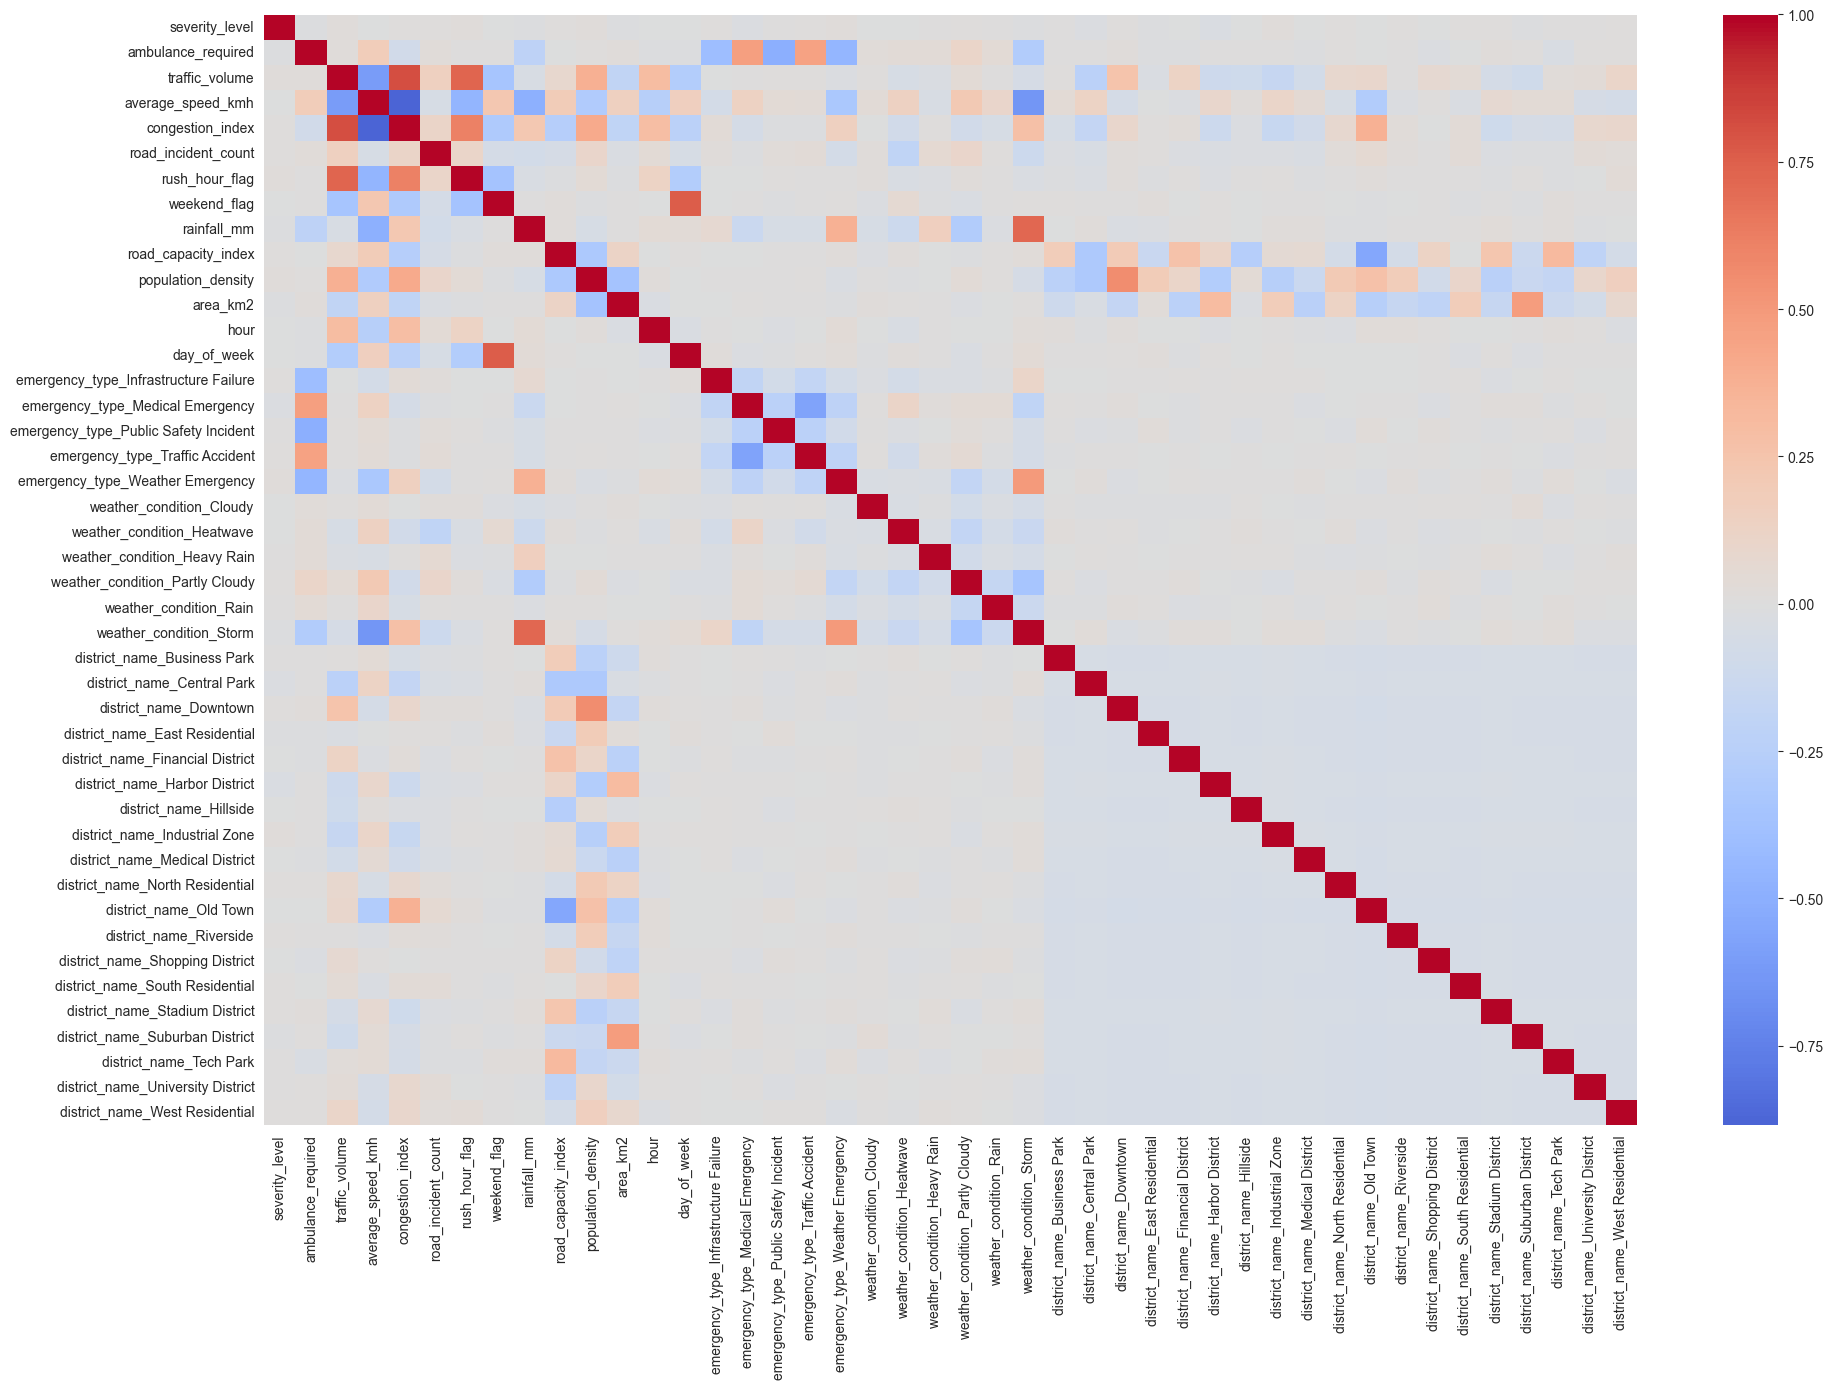

In [19]:
correlation = X_train.corr()
plt.figure(figsize=(20, 14))
sns.heatmap(correlation, cmap='coolwarm', center=0)
plt.tight_layout()
plt.show()

# Model Training

## Training

In [20]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](44,)","[-2.9 , 0.07, 0.01,..., 0.05, 0.04, 0.05]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](44,)","['severity_level','ambulance_required','traffic_volume',..., 'district_name_Tech Park','district_name_University District', 'district_name_West Residential']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,19.36
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,44
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,40


## Evaluating

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = model.predict(X_test)

print('MAE:', mean_absolute_error(y_test, y_pred))
print('RMSE:', mean_squared_error(y_test, y_pred) ** 0.5)
print('R²:', r2_score(y_test, y_pred))

MAE: 1.7038558657499614
RMSE: 2.143792471376704
R²: 0.9461796970757095
